# Volume meshes on an octree

`octree_mesh` meshes the inside of a skin on a 2:1-balanced octree. The skin can be any surface, closed or slightly dirty: inside and outside come from the fast generalised winding number. The leaves follow a size field (curvature, sharp features, thin gaps, a user array) between `min_size` and `max_size`.

It has two outputs today:

- **`output="tet"`** (the default): conforming graded tetrahedra. The tree is tetrahedralised as a graded BCC lattice and cut to the skin by isosurface stuffing. Sharp corners and edges are snapped, then the mesh is optimised without ever worsening its extreme dihedral angles.
- **`output="castellated"`**: the inside leaves as hexahedra, with the `surrogate_boundary` side region and the signed distance and closest point at the nodes, for embedded and Shifted Boundary Method solvers.

It is also a CLI verb, a pipeline step and an MCP tool: `meshioplusplus octree-mesh skin.stl out.vtu --min-size 0.02`.

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
    pv.set_jupyter_backend('static')
except Exception:  # pragma: no cover - PyVista is optional
    pv = None

DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')


def save_img(name, img=None):
    """Write a render (or the current matplotlib figure) to doc/public/images/<name>.png."""
    try:
        os.makedirs(DOC_IMAGES, exist_ok=True)
        path = os.path.join(DOC_IMAGES, name + '.png')
        if img is None:
            plt.savefig(path, dpi=110, bbox_inches='tight')
        else:
            plt.imsave(path, img)
    except Exception as exc:  # pragma: no cover - read-only checkout
        print('doc image not written:', exc)


def gl_available():
    """Probe off-screen GL in a child process: a missing GL stack can kill the
    interpreter outright, which no try/except in this one would survive."""
    if pv is None:
        return False
    import subprocess, sys
    probe = ('import pyvista as pv; pv.OFF_SCREEN = True; pl = pv.Plotter(off_screen=True); '
             'pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)')
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True,
                              timeout=120).returncode == 0
    except Exception:
        return False


GL = gl_available()
print('PyVista rendering' if GL else 'matplotlib fallback (no off-screen GL)')


def to_pyvista(mesh):
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


FACES = {'tetra': [(0, 1, 3), (1, 2, 3), (2, 0, 3), (0, 2, 1)],
         'hexahedron': [(0, 3, 2, 1), (4, 5, 6, 7), (0, 1, 5, 4), (1, 2, 6, 5), (2, 3, 7, 6), (3, 0, 4, 7)]}


def clipped_faces(mesh, values):
    """The boundary faces of the cells whose centroid has y < 0, with the cell values."""
    pts = np.asarray(mesh.points)
    cb = mesh.cells[0]
    conn = np.asarray(cb.data)
    keep = pts[conn].mean(axis=1)[:, 1] < 0
    seen = {}
    for c in np.nonzero(keep)[0]:
        for f in FACES[cb.type]:
            key = tuple(sorted(conn[c, list(f)]))
            seen[key] = None if key in seen else (conn[c, list(f)], values[c])
    faces = [v for v in seen.values() if v is not None]
    return [pts[f] for f, _ in faces], np.array([v for _, v in faces])


def render(mesh, scalars, title, save, cmap='viridis', clim=None):
    """The half y < 0 of a volume mesh coloured by a cell array: PyVista when
    GL is available, else a matplotlib 3-D collection of its boundary faces."""
    values = np.asarray(mesh.cell_data[scalars][0], dtype=float)
    if GL:
        grid = to_pyvista(mesh)
        half = grid.clip(normal='y', origin=(0, 0, 0), crinkle=True)
        pl = pv.Plotter(off_screen=True, window_size=(900, 700))
        pl.add_mesh(half, scalars=scalars, cmap=cmap, clim=clim, show_edges=True,
                    edge_color='#333333', line_width=0.3)
        pl.view_xz(negative=True)
        pl.camera.elevation = 20
        pl.camera.azimuth = 25
        img = pl.screenshot(return_img=True)
        pl.close()
        save_img(save, img)
        plt.figure(figsize=(9, 7)); plt.imshow(img); plt.axis('off'); plt.title(title); plt.show()
        return
    polys, vals = clipped_faces(mesh, values)
    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(projection='3d')
    lo, hi = (vals.min(), vals.max()) if clim is None else clim
    colours = plt.get_cmap(cmap)((vals - lo) / max(hi - lo, 1e-12))
    ax.add_collection3d(Poly3DCollection(polys, facecolors=colours, edgecolors='k', linewidths=0.15))
    p = np.asarray(mesh.points)
    ax.set_xlim(p[:, 0].min(), p[:, 0].max()); ax.set_ylim(p[:, 1].min(), p[:, 1].max())
    ax.set_zlim(p[:, 2].min(), p[:, 2].max()); ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=18, azim=62); ax.set_axis_off(); ax.set_title(title)
    save_img(save)
    plt.show()


def tet_volumes(mesh):
    p = np.asarray(mesh.points)
    t = np.asarray(mesh.cells[0].data)
    a, b, c, d = (p[t[:, k]] for k in range(4))
    return np.einsum('ij,ij->i', b - a, np.cross(c - a, d - a)) / 6.0


def show_report(report, keys):
    for k in keys:
        v = report[k]
        print(f'{k:32s} {v:.4g}' if isinstance(v, float) else f'{k:32s} {v}')
    for w in report['warnings']:
        print('warning:', w)

matplotlib fallback (no off-screen GL)


## Castellated cells around a sphere

`output="castellated"` keeps the leaves whose centre is inside (`fill="inside"`). A leaf the skin cuts is split until it is no larger than the size its triangles ask for, and the leaves coarsen towards `max_size` away from the skin. `min_size` and `max_size` only clamp the size field. What refines is its criteria: here `curvature_angle`, the angle a leaf edge may subtend on the skin (15° by default, which on a unit sphere asks for about 0.26). The `surrogate_boundary` side region holds the faces of inside cells with no inside cell across them, which is the surrogate boundary of the Shifted Boundary Method. Its faces enclose exactly the inside cells' volume, which converges to 4/3 π. The nodes carry `sdf:distance` (negative inside) and `sdf:closest_point`.

In [2]:
sphere = mp.icosa_sphere(1.0, 4)
cells, rep = mp.octree_mesh(sphere, output='castellated', curvature_angle=6, min_size=0.02,
                            max_size=0.4, return_report=True)
show_report(rep, ['num_leaves', 'num_hexahedra', 'num_boundary_cells', 'num_surrogate_faces',
                  'num_hanging', 'finest_level'])
names = {r.name: r for r in cells.regions}
print('regions:', sorted(names), '- surrogate faces:', len(names['surrogate_boundary'].entries))
sdf = np.asarray(cells.point_data['sdf:distance'])
print(f'sdf:distance from {sdf.min():.3f} to {sdf.max():.3f}')

for angle in (24, 12, 6, 3):
    c, r = mp.octree_mesh(sphere, output='castellated', curvature_angle=angle, min_size=0.01,
                          max_size=0.4, return_report=True)
    edge = r['root_size'] / 2.0 ** np.asarray(c.cell_data['octree:level'][0])
    vol = float(np.sum(edge ** 3))
    print(f'curvature_angle {angle:2d}: {r["num_hexahedra"]:6d} cells, volume {vol:.4f}, '
          f'error {abs(vol - 4 / 3 * np.pi) / (4 / 3 * np.pi):.2%}')

num_leaves                       14160
num_hexahedra                    4728
num_boundary_cells               1320
num_surrogate_faces              2904
num_hanging                      1440
finest_level                     3
regions: ['boundary_cells', 'inside', 'surrogate_boundary'] - surrogate faces: 2904
sdf:distance from -0.999 to 0.065


curvature_angle 24:    136 cells, volume 4.4564, error 6.39%
curvature_angle 12:   1008 cells, volume 4.3581, error 4.04%


curvature_angle  6:   4728 cells, volume 4.1697, error 0.46%


curvature_angle  3:  24552 cells, volume 4.1805, error 0.20%


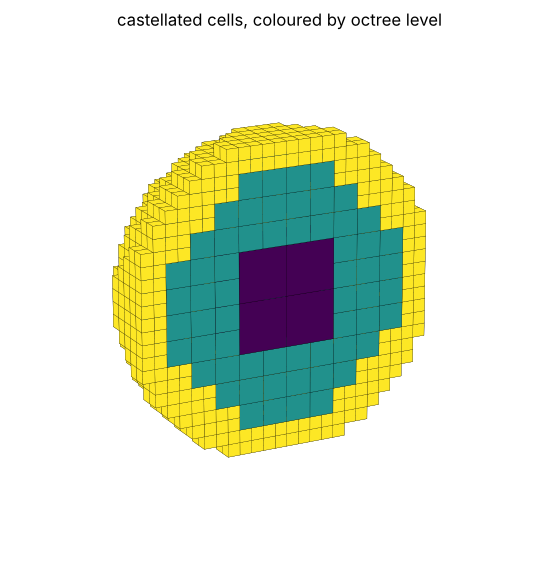

In [3]:
render(cells, 'octree:level', 'castellated cells, coloured by octree level', 'octree_mesh_castellated')

## Conforming tetrahedra (the default)

The default output is a conforming graded tetrahedral mesh of the inside. The balanced tree is tetrahedralised as a graded body-centred cubic lattice (six shapes, dihedral angles from 35.26° to 125.26°). Isosurface stuffing (Labelle and Shewchuk 2007) then cuts it to the skin: lattice vertices close to the skin are warped onto it and the tetrahedra the skin crosses are cut by stencils. Last, `fit_iterations` rounds of optimisation (ODT relocation, sliding along the skin, flips) improve the mesh without ever lowering its smallest dihedral angle or raising its largest. The report carries the angles, the scaled Jacobian, the two-sided Hausdorff distance between the boundary and the skin, and the boundary's manifoldness.

In [4]:
SIZES = dict(curvature_angle=8, min_size=0.02, max_size=0.4)
tets, rep = mp.octree_mesh(sphere, return_report=True, **SIZES)
show_report(rep, ['num_tetrahedra', 'num_cut_points', 'num_warped', 'min_dihedral', 'max_dihedral',
                  'min_scaled_jacobian', 'num_inverted', 'hausdorff_to_skin',
                  'num_boundary_edges_open', 'num_non_manifold_boundary_edges',
                  'num_optimized_moves', 'num_flips'])
vol = tet_volumes(tets)
print(f'all positive: {bool(np.all(vol > 0))}, volume {vol.sum():.4f} (4/3 pi = {4 / 3 * np.pi:.4f})')
print('stage timings (s):', {k: round(v, 3) for k, v in rep['timings'].items()})

num_tetrahedra                   72360
num_cut_points                   1790
num_warped                       2292
min_dihedral                     25.58
max_dihedral                     129.7
min_scaled_jacobian              0.2302
num_inverted                     0
hausdorff_to_skin                0.002058
num_boundary_edges_open          0
num_non_manifold_boundary_edges  0
num_optimized_moves              10859
num_flips                        120
all positive: True, volume 4.1727 (4/3 pi = 4.1888)
stage timings (s): {'skin': 0.013, 'size_field': 0.006, 'octree': 0.015, 'stuffing': 0.336, 'features': 0.0, 'optimize': 1.15, 'output': 0.248, 'quality': 0.009}


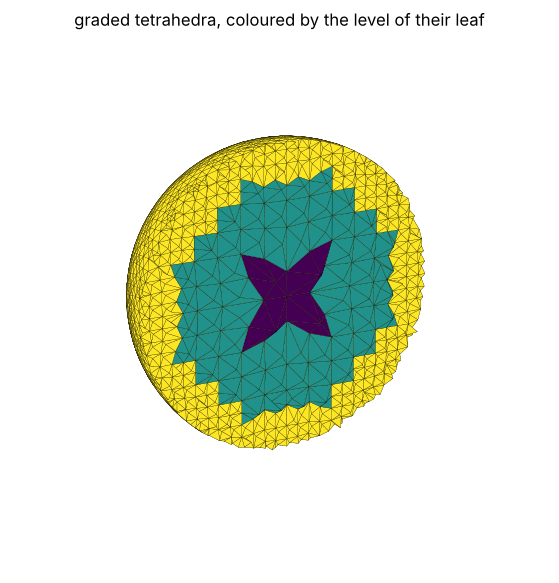

In [5]:
render(tets, 'octree:level', 'graded tetrahedra, coloured by the level of their leaf', 'octree_mesh_tets')

## The dihedral angles, before and after optimisation

`fit_iterations=0` gives the stuffed lattice as it is. The default five rounds move the interior nodes towards their optimal-Delaunay positions and slide the skin nodes along it, and the guard keeps the extremes where they were or better. With `skin_grading="uniform"`, every tetrahedron near the skin is cut from the uniform BCC lattice and Labelle and Shewchuk's 10.7°–164.8° bound holds (`guarantee_applies`).

graded   guarantee_applies=False


uniform  guarantee_applies=True


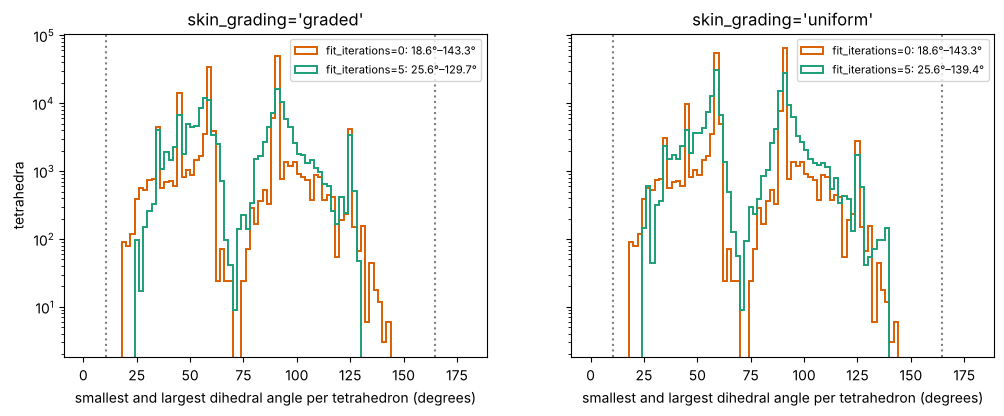

In [6]:
def dihedrals(mesh):
    q = mp.attach_quality(mesh)
    return (np.asarray(q.cell_data['quality:min_dihedral'][0]),
            np.asarray(q.cell_data['quality:max_dihedral'][0]))


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (label, kw) in zip(axes, [('graded', {}), ('uniform', dict(skin_grading='uniform'))]):
    for fit, colour in ((0, '#d95f02'), (5, '#1b9e77')):
        m, r = mp.octree_mesh(sphere, fit_iterations=fit, return_report=True, **SIZES, **kw)
        lo, hi = dihedrals(m)
        ax.hist(np.concatenate([lo, hi]), bins=90, range=(0, 180), histtype='step', color=colour,
                lw=1.4, label=f'fit_iterations={fit}: {r["min_dihedral"]:.1f}°–{r["max_dihedral"]:.1f}°')
        if fit == 5:
            print(f'{label:8s} guarantee_applies={r["guarantee_applies"]}')
    ax.axvline(10.7, color='grey', ls=':'); ax.axvline(164.8, color='grey', ls=':')
    ax.set_yscale('log'); ax.set_xlabel('smallest and largest dihedral angle per tetrahedron (degrees)')
    ax.set_title(f'skin_grading={label!r}'); ax.legend(fontsize=8)
axes[0].set_ylabel('tetrahedra')
save_img('octree_mesh_dihedrals')
plt.show()

## Sharp features

With `preserve_features` (the default), the skin's edges sharper than `feature_angle` form a graph of corners and chains. Each corner moves the nearest boundary node onto itself exactly. Each chain is traced on the boundary by a shortest path in a tube around it, and the path's nodes move onto the chain. A move is refused if it would invert a tetrahedron or create a sliver, and whatever cannot be recovered is counted and reported in `warnings`. The nodes on features are the `feature_corners` and `feature_edges` point regions.

In [7]:
L, lo = 1.37, [-0.61, -0.67, -0.7]
cube = mp.convert_cells(mp.extract_surface(mp.box([8, 8, 8], [L, L, L], lo)), mode='simplexify')
ctets, rep = mp.octree_mesh(cube, min_size=0.05, max_size=0.4, return_report=True)
show_report(rep, ['num_corners', 'num_corners_snapped', 'num_feature_chains',
                  'num_feature_chains_missed', 'num_feature_moves', 'min_dihedral', 'max_dihedral'])
p = np.asarray(ctets.points)
corners = np.array([[lo[0] + (i & 1) * L, lo[1] + (i >> 1 & 1) * L, lo[2] + (i >> 2 & 1) * L] for i in range(8)])
print('largest corner miss:', max(np.min(np.linalg.norm(p - c, axis=1)) for c in corners))
regions = {r.name: r for r in ctets.regions}
edge_nodes = np.asarray(regions['feature_edges'].entries).ravel()
on = (np.abs(p[edge_nodes] - lo) < 1e-12) | (np.abs(p[edge_nodes] - np.add(lo, L)) < 1e-12)
print('feature-edge nodes on two cube faces:', bool(np.all(on.sum(axis=1) >= 2)), f'({len(edge_nodes)} nodes)')

num_corners                      8
num_corners_snapped              8
num_feature_chains               12
num_feature_chains_missed        0
num_feature_moves                1280
min_dihedral                     29.5
max_dihedral                     128.9
largest corner miss: 0.0
feature-edge nodes on two cube faces: True (320 nodes)


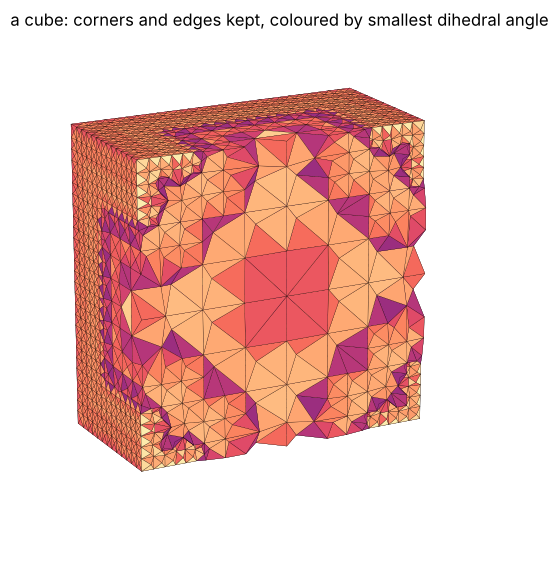

In [8]:
ctets.cell_data['min dihedral'] = [dihedrals(ctets)[0]]
render(ctets, 'min dihedral', 'a cube: corners and edges kept, coloured by smallest dihedral angle',
       'octree_mesh_cube', cmap='magma', clim=(0, 70))

## Nested shells and dirty skins

`conformity="cleaving"` meshes a skin whose winding number reaches 2 or more, such as a sphere inside a sphere. It stuffs the interface at each winding level in turn, holding the earlier ones fixed, so the materials conform; they are the `material_<k>` cell regions and `octree_mesh:material` cell data. A skin with holes still meshes: the winding number is ½ across a hole, and the cut there is placed by bisection.

In [9]:
outer, inner = mp.icosa_sphere(1.0, 4), mp.icosa_sphere(0.5, 3)
both = mp.merge([outer, inner])
nested, rep = mp.octree_mesh(both, conformity='cleaving', min_size=0.05, max_size=0.4,
                             return_report=True)
material = np.asarray(nested.cell_data['octree_mesh:material'][0])
vol = tet_volumes(nested)
for k in np.unique(material):
    print(f'material {k}: {np.sum(material == k):6d} tetrahedra, volume {vol[material == k].sum():.4f}')
print(f'(analytic: shell {4 / 3 * np.pi * (1 - 0.125):.4f}, core {4 / 3 * np.pi * 0.125:.4f})')

holed = mp.Mesh(np.asarray(sphere.points),
                [('triangle', np.delete(np.asarray(sphere.cells[0].data), np.s_[::13], axis=0))])
h, hr = mp.octree_mesh(holed, min_size=0.05, max_size=0.4, return_report=True)
print(f'a sphere missing every 13th triangle: {hr["num_tetrahedra"]} tetrahedra, '
      f'volume {tet_volumes(h).sum():.4f}, inverted {hr["num_inverted"]}')

material 1:  23880 tetrahedra, volume 3.6238
material 2:   6768 tetrahedra, volume 0.5136
(analytic: shell 3.6652, core 0.5236)


a sphere missing every 13th triangle: 6864 tetrahedra, volume 4.1363, inverted 0


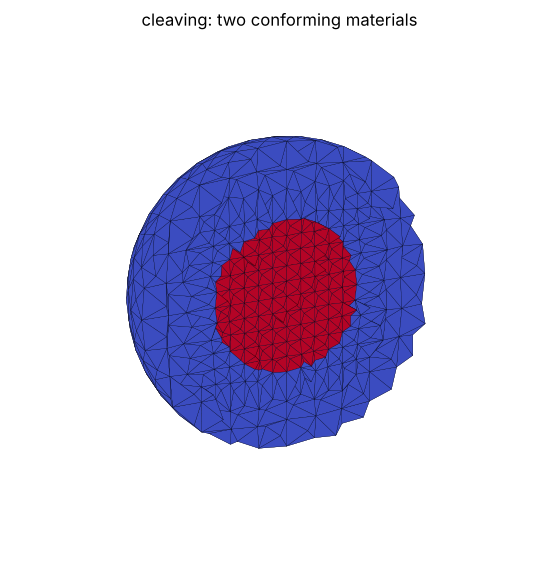

In [10]:
render(nested, 'octree_mesh:material', 'cleaving: two conforming materials', 'octree_mesh_cleaving',
       cmap='coolwarm')